In [6]:
!pip install pytorch_wavelets


In [4]:
!pip install torchsummary

  Using cached torchsummary-1.5.1-py3-none-any.whl.metadata (296 bytes)
Using cached torchsummary-1.5.1-py3-none-any.whl (2.8 kB)


In [7]:
import os
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
import torchvision.models as models
from pytorch_wavelets import DTCWTForward

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cpu


/opt/anaconda3/envs/tf/lib/python3.11/site-packages/pytorch_wavelets/dtcwt/coeffs.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream


### Apply the 3-level DTCWT on one image


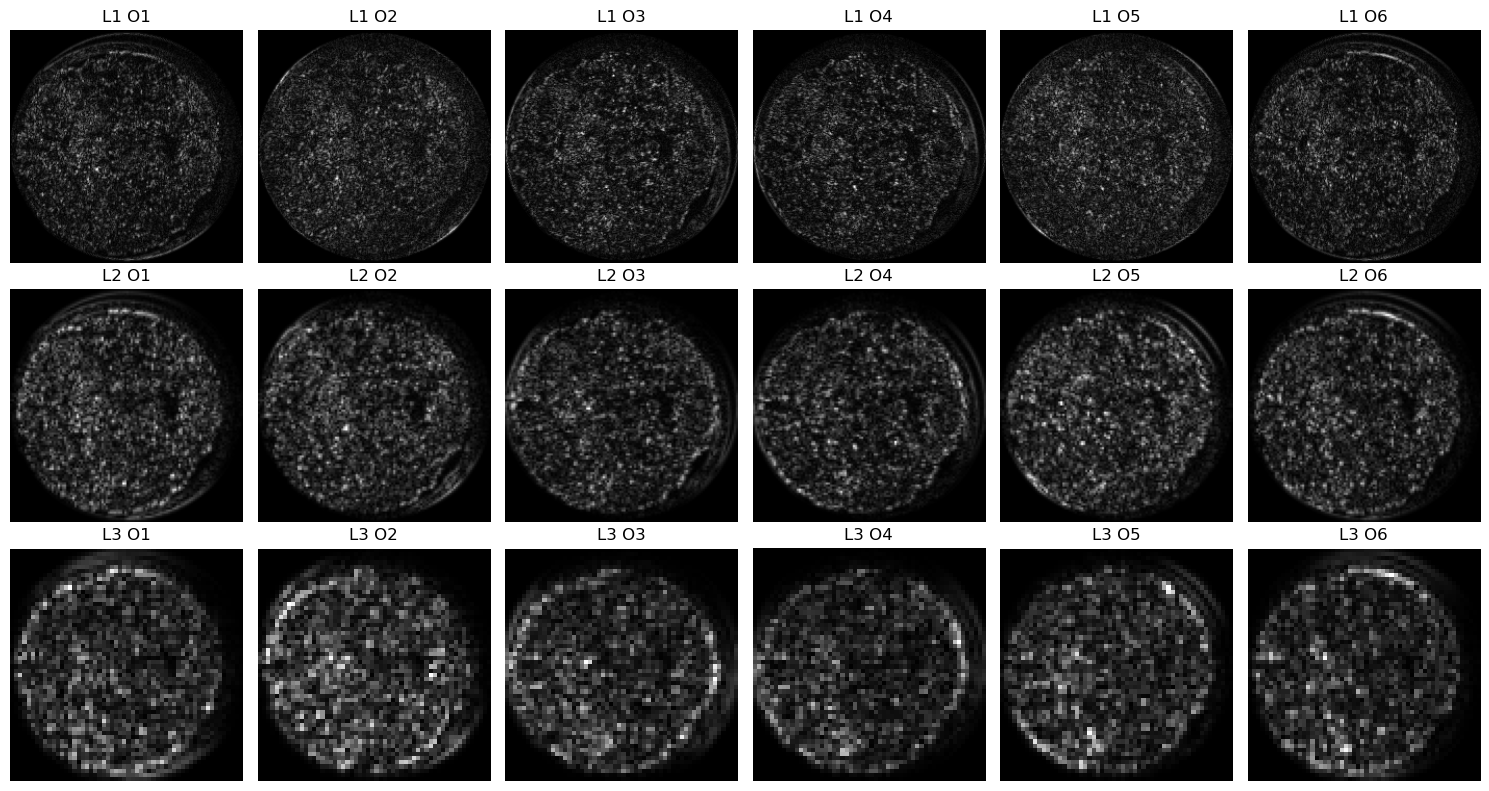

In [99]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from pytorch_wavelets import DTCWTForward

# Load image
img = Image.open("/Users/amani.khalid/Desktop/SRP 2/data/tif_pages_cylinders/page_3.png").convert("L")
img = img.resize((448, 448))
img_np = np.array(img, dtype=np.float32) / 255.0
x = torch.from_numpy(img_np).unsqueeze(0).unsqueeze(0)  # [1, 1, H, W]

xfm = DTCWTForward(J=3, biort='near_sym_b', qshift='qshift_b')
Yl, Yh = xfm(x)

# Visualise the magnitude of the 6 oriented subbands at each level
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for level_idx, level in enumerate(Yh):
    # level: [N, C, 6, H, W, 2]
    real = level[0, 0, :, :, :, 0]
    imag = level[0, 0, :, :, :, 1]
    mag = torch.sqrt(real ** 2 + imag ** 2)
    for ori in range(6):
        axes[level_idx, ori].imshow(mag[ori].cpu().numpy(), cmap='gray')
        axes[level_idx, ori].set_title(f'L{level_idx+1} O{ori+1}')
        axes[level_idx, ori].axis('off')

plt.tight_layout()
plt.show()


### Image processing (data)

In [17]:
import os
import random
from typing import Tuple, List
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

IMG_SIZE = 448

base_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
])

class PathImageDataset(Dataset):
    """
    Dataset from a list of (img_path, label_index) pairs.
    Returns (tensor_image, label).
    """
    def __init__(self, samples: List[Tuple[str, int]], classes: List[str], transform=None):
        self.samples = samples
        self.classes = classes
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = Image.open(img_path).convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        return img, label


def make_dtcwt_dataloaders(
    data_root,
    batch_size=8,
    val_ratio=0.1,
    test_ratio=0.1,
    C_keep=16,
    energy_max_samples=None,
    seed=42,
    include_lowpass=True,
):
    """
    data_root: folder with class subfolders
    Returns:
        train_loader, val_loader, test_loader, class_names, selected_channels
    """
    assert os.path.isdir(data_root), f"{data_root} does not exist"

    full_base = ImageFolder(root=data_root)  # no transform -> raw PIL images
    class_names = full_base.classes
    print("Classes:", class_names)

    n_total = len(full_base)
    n_val = int(n_total * val_ratio)
    n_test = int(n_total * test_ratio)
    n_train = n_total - n_val - n_test

    g = torch.Generator().manual_seed(seed)
    train_base, val_base, test_base = random_split(full_base, [n_train, n_val, n_test], generator=g)

    print(f"Total images: {n_total}")
    print(f"Train: {len(train_base)}, Val: {len(val_base)}, Test: {len(test_base)}")

    selected_channels = select_top_dtcwt_channels(
        train_base,
        C_keep=C_keep,
        max_samples=energy_max_samples,
        include_lowpass=include_lowpass,
    )

    train_ds = DTCWTDataset(train_base, selected_channels, include_lowpass=include_lowpass)
    val_ds   = DTCWTDataset(val_base,   selected_channels, include_lowpass=include_lowpass)
    test_ds  = DTCWTDataset(test_base,  selected_channels, include_lowpass=include_lowpass)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=False)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=False)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=False)

    return train_loader, val_loader, test_loader, class_names, selected_channels


### 2D Dual-Tree Complex Wavelet Transform (3-level)


In [20]:
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
import torchvision.transforms as T
from pytorch_wavelets import DTCWTForward

resize_tf = T.Resize((IMG_SIZE, IMG_SIZE))
_dtcwt = DTCWTForward(J=3, biort='near_sym_b', qshift='qshift_b')

def dtcwt_3level(img_pil: Image.Image, include_lowpass: bool = True) -> torch.Tensor:
    """
    Apply 3-level 2D DTCWT and return tensor [C, 56, 56].

    Channel layout:
      - optional lowpass at level 3: 1 channel
      - 6 oriented magnitude channels for each of 3 levels: 18 channels

    Total channels with include_lowpass=True: 19
    """
    # 1) Resize and convert to grayscale to mirror the original WPT pipeline
    img_pil = resize_tf(img_pil)
    img_gray = img_pil.convert("L")

    # 2) To tensor [1, 1, H, W]
    img_np = np.array(img_gray, dtype=np.float32) / 255.0
    x = torch.from_numpy(img_np).unsqueeze(0).unsqueeze(0)

    # 3) DTCWT
    Yl, Yh = _dtcwt(x)

    # 4) Use deepest lowpass size as the common size (for 448x448 and J=3 this is 56x56)
    target_h, target_w = Yl.shape[-2], Yl.shape[-1]
    subbands = []

    if include_lowpass:
        subbands.append(Yl.squeeze(0))  # [1, 56, 56]

    # 5) Convert complex highpasses to magnitude channels and pool every level to [56, 56]
    for level in Yh:
        # level: [1, 1, 6, H, W, 2]
        real = level[..., 0]  # [1, 1, 6, H, W]
        imag = level[..., 1]  # [1, 1, 6, H, W]
        mag = torch.sqrt(real ** 2 + imag ** 2 + 1e-12)

        mag = mag.squeeze(0).squeeze(0)  # [6, H, W]
        if mag.shape[-2:] != (target_h, target_w):
            mag = F.adaptive_avg_pool2d(mag.unsqueeze(0), (target_h, target_w)).squeeze(0)

        subbands.append(mag)

    # 6) Stack into [19, 56, 56]
    W = torch.cat(subbands, dim=0).float()
    return W


### Selection (Energy-based, DTCWT channels)


In [23]:
def compute_channel_energy_dtcwt(train_base_dataset, max_samples=None, include_lowpass=True):
    """
    train_base_dataset: dataset that returns (PIL_image, label)
    Returns: np.array of shape (19,) when include_lowpass=True,
             or (18,) when include_lowpass=False.
    """
    sum_energy = None
    total_pixels = 0

    n_samples = len(train_base_dataset) if max_samples is None else min(len(train_base_dataset), max_samples)

    for idx in range(n_samples):
        img, _ = train_base_dataset[idx]  # PIL image
        W = dtcwt_3level(img, include_lowpass=include_lowpass)  # [C, 56, 56]

        C, H, W_sub = W.shape
        energy = (W ** 2).sum(dim=(1, 2))  # [C]

        if sum_energy is None:
            sum_energy = energy
        else:
            sum_energy += energy

        total_pixels += H * W_sub

    avg_energy = (sum_energy / float(total_pixels)).cpu().numpy()
    return avg_energy


def select_top_dtcwt_channels(train_base_dataset, C_keep=16, max_samples=None, include_lowpass=True):
    """
    Compute avg energies and return list of top-K DTCWT channel indices.
    """
    avg_energy = compute_channel_energy_dtcwt(
        train_base_dataset,
        max_samples=max_samples,
        include_lowpass=include_lowpass,
    )

    total_channels = len(avg_energy)
    C_keep = min(C_keep, total_channels)
    top_idx = np.argsort(-avg_energy)[:C_keep]
    selected_channels = sorted(top_idx.tolist())
    print(f"Selected DTCWT channels (keeping {C_keep}/{total_channels}):", selected_channels)
    return selected_channels


### Selected DTCWT subbands (highest energies)


In [26]:
class DTCWTDataset(Dataset):
    """
    Wraps a base dataset that returns (PIL_image, label).
    For each item, applies 3-level DTCWT and keeps only selected channels.
    Returns (W_sel, label) where W_sel: [C_keep, 56, 56].
    """
    def __init__(self, base_dataset, selected_channels, include_lowpass=True):
        self.base = base_dataset
        self.selected_channels = selected_channels
        self.include_lowpass = include_lowpass

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        img, label = self.base[idx]   # PIL image (no transforms)
        W = dtcwt_3level(img, include_lowpass=self.include_lowpass)  # [19, 56, 56]
        W_sel = W[self.selected_channels, :, :]
        return W_sel, label


### The CNN Structrue (Modified ResNet50)

In [29]:
import torch
import torch.nn as nn
import torchvision.models as models

class DTCWTResNet50(nn.Module):
    def __init__(self, num_classes, in_channels):
        super().__init__()
        base = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)

        old_conv = base.conv1
        base.conv1 = nn.Conv2d(
            in_channels,
            old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            bias=False,
        )

        with torch.no_grad():
            if in_channels == 1:
                base.conv1.weight[:] = old_conv.weight.mean(dim=1, keepdim=True)
            elif in_channels == 3:
                base.conv1.weight.copy_(old_conv.weight)
            else:
                copy_channels = min(3, in_channels)
                base.conv1.weight[:, :copy_channels, :, :] = old_conv.weight[:, :copy_channels, :, :]
                if in_channels > 3:
                    extra = in_channels - 3
                    mean_extra = old_conv.weight.mean(dim=1, keepdim=True)
                    base.conv1.weight[:, 3:3+extra, :, :] = mean_extra.repeat(1, extra, 1, 1)

        in_feats = base.fc.in_features
        base.fc = nn.Linear(in_feats, num_classes)
        self.model = base

    def forward(self, x):
        # x: [B, C_keep, 56, 56]
        return self.model(x)


### Train and validation loop

In [32]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for W_sel, labels in loader:  # W_sel: [B, C_keep, H_sub, W_sub]
        W_sel = W_sel.to(device).float()
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(W_sel)  # [B, num_classes]
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)

    return running_loss / total, (correct / total)*100


def eval_one_epoch(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for W_sel, labels in loader:
            W_sel = W_sel.to(device).float()
            labels = labels.to(device)

            outputs = model(W_sel)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * labels.size(0)
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)

    return running_loss / total, (correct / total)*100

### Train the model 

In [113]:
data_root = '/Users/amani.khalid/Desktop/SRP 2/Rock Data/train'  # update this

batch_size = 8
C_keep = 8          # DTCWT with lowpass gives 19 total channels at J=3
num_epochs = 20
energy_max_samples = None  # or e.g. 200 if you want faster energy estimation
include_lowpass = True

train_loader, val_loader, test_loader, class_names, selected_channels = make_dtcwt_dataloaders(
    data_root=data_root,
    batch_size=batch_size,
    val_ratio=0.1,
    test_ratio=0.1,
    C_keep=C_keep,
    energy_max_samples=energy_max_samples,
    seed=42,
    include_lowpass=include_lowpass,
)

num_classes = len(class_names)

train_acc_list = []
val_acc_list = []

train_loss_list = []
val_loss_list = []

model = DTCWTResNet50(num_classes=num_classes, in_channels=len(selected_channels)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

for epoch in range(num_epochs):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = eval_one_epoch(model, val_loader, criterion, device)

    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)
    train_loss_list.append(train_loss)
    val_loss_list.append(val_loss)

    print(f"Epoch {epoch+1}/{num_epochs}: "
          f"Train loss: {train_loss:.4f}, acc: {train_acc:.2f}%  | "
          f"Val loss {val_loss:.4f}, acc: {val_acc:.2f}%")


Classes: ['Basalt', 'Class 1', 'Class 2', 'Class 3', 'Clay', 'Conglomerate', 'Diatomite', 'Shale-(Mudstone)', 'Siliceous-sinter', 'chert', 'gypsum', 'olivine-basalt']
Total images: 3854
Train: 3084, Val: 385, Test: 385
Selected DTCWT channels (keeping 8/19): [0, 10, 13, 14, 15, 16, 17, 18]
Epoch 1/20: Train loss: 1.8163, acc: 36.25%  | Val loss 1.2076, acc: 61.30%
Epoch 2/20: Train loss: 1.0525, acc: 64.46%  | Val loss 0.8373, acc: 70.91%
Epoch 3/20: Train loss: 0.6021, acc: 80.71%  | Val loss 0.8511, acc: 70.13%
Epoch 4/20: Train loss: 0.3559, acc: 89.14%  | Val loss 0.7872, acc: 75.84%
Epoch 5/20: Train loss: 0.2462, acc: 92.44%  | Val loss 0.5438, acc: 82.60%
Epoch 6/20: Train loss: 0.2057, acc: 93.19%  | Val loss 0.6624, acc: 78.96%
Epoch 7/20: Train loss: 0.1642, acc: 94.81%  | Val loss 0.7440, acc: 77.40%
Epoch 8/20: Train loss: 0.1283, acc: 96.21%  | Val loss 0.5814, acc: 82.08%
Epoch 9/20: Train loss: 0.1343, acc: 95.72%  | Val loss 0.7783, acc: 80.00%
Epoch 10/20: Train loss: 

In [114]:
print(model)

DTCWTResNet50(
  (model): ResNet(
    (conv1): Conv2d(8, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Sequential(
      

 Average accuracy on validation set is 79.45454545454545


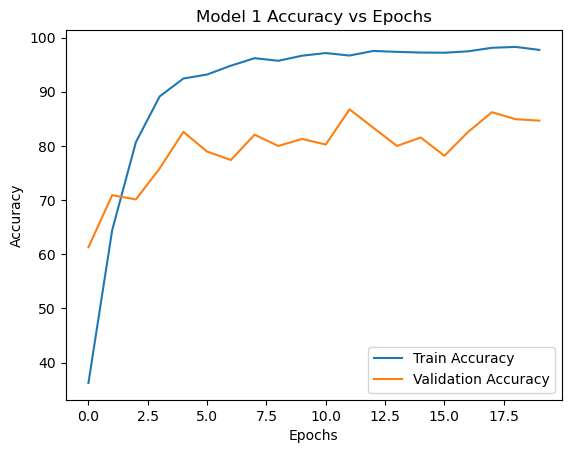

In [115]:
import matplotlib.pyplot as plt

avg_val_acc = sum(val_acc_list)/20
print(f' Average accuracy on validation set is {avg_val_acc}')

plt.title('Model 1 Accuracy vs Epochs')
plt.plot(train_acc_list, label='Train Accuracy')
plt.plot(val_acc_list, label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [116]:
# Final test evaluation
test_loss, test_acc = eval_one_epoch(model, test_loader, criterion, device)
print(f"Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}%")

Test loss: 0.5871, Test acc: 82.8571%


In [135]:
for epoch in range(31):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = eval_one_epoch(model, val_loader, criterion, device)

    train_acc_list.append(train_acc)
    val_acc_list.append(val_acc)
    train_loss_list.append(train_loss)
    val_loss_list.append(val_loss)

    print(f"Epoch {epoch+20}/{50}: "
          f"Train loss: {train_loss:.4f}, acc: {train_acc:.2f}%  | "
          f"Val loss {val_loss:.4f}, acc: {val_acc:.2f}%")

Epoch 20/50: Train loss: 0.0458, acc: 98.54%  | Val loss 0.5030, acc: 84.42%
Epoch 21/50: Train loss: 0.0538, acc: 98.35%  | Val loss 0.5522, acc: 85.97%
Epoch 22/50: Train loss: 0.0445, acc: 98.48%  | Val loss 0.8010, acc: 81.04%
Epoch 23/50: Train loss: 0.0678, acc: 97.73%  | Val loss 0.5786, acc: 81.82%
Epoch 24/50: Train loss: 0.0509, acc: 98.25%  | Val loss 0.6748, acc: 82.60%
Epoch 25/50: Train loss: 0.0509, acc: 98.18%  | Val loss 0.5414, acc: 85.45%
Epoch 26/50: Train loss: 0.0635, acc: 97.80%  | Val loss 0.6125, acc: 84.42%
Epoch 27/50: Train loss: 0.0382, acc: 98.77%  | Val loss 0.4708, acc: 86.49%
Epoch 28/50: Train loss: 0.0433, acc: 98.57%  | Val loss 0.5634, acc: 83.12%
Epoch 29/50: Train loss: 0.0460, acc: 98.12%  | Val loss 0.5998, acc: 82.34%
Epoch 30/50: Train loss: 0.0394, acc: 98.44%  | Val loss 0.6553, acc: 82.60%
Epoch 31/50: Train loss: 0.0365, acc: 98.74%  | Val loss 0.7299, acc: 81.82%
Epoch 32/50: Train loss: 0.0426, acc: 98.25%  | Val loss 0.6559, acc: 83.90%

In [154]:
test_loss, test_acc = eval_one_epoch(model, test_loader, criterion, device)
print(f"Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}%")

Test loss: 0.9173, Test acc: 80.7792%


In [160]:
class_names

['Class 1', 'Class 2', 'Class 3']

In [156]:
import torch

torch.save({
     "model_state": model.state_dict(),
    "selected_channels": selected_channels,
    "class_names": class_names
 }, "dtcwt_resNet50_rockandReal2(new).pth")


[[32  0  0  0  1  0  1  0  0  1  0  1]
 [ 0  3  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  7  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  3  0  0  0  0  0  0  0  0]
 [ 1  0  0  0 39  0  1  0  0  1  0  1]
 [ 0  0  0  0  4 31  0  2  2  0  0  2]
 [ 0  0  0  0  2  0 41  1  0  0  1  2]
 [ 1  0  0  0  9  0  3 27  0  3  0  0]
 [ 0  0  0  0  1  1  0  2 31  1  0  0]
 [ 1  0  0  0  2  1  0  3  1 46  0  0]
 [ 1  0  0  0  3  4  2  2  3  3 26  0]
 [ 2  0  0  0  2  1  0  4  0  0  0 19]]


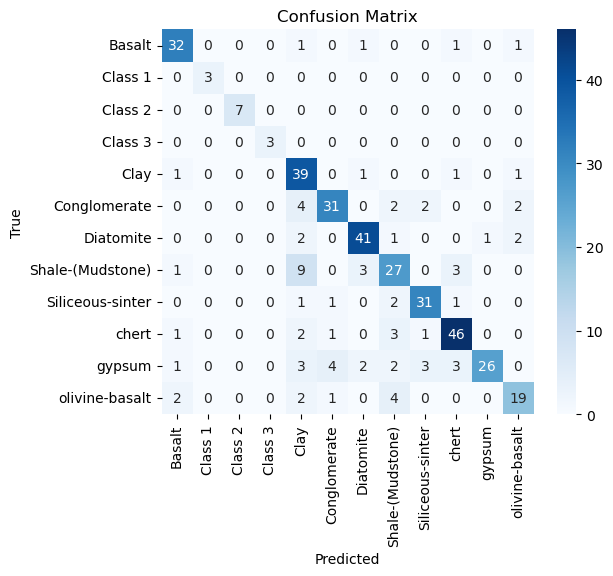

In [162]:
import torch
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

model.eval()

all_preds = []
all_labels = []

classes= ['Basalt', 'Class 1', 'Class 2', 'Class 3', 'Clay', 'Conglomerate', 'Diatomite', 'Shale-(Mudstone)', 'Siliceous-sinter', 'chert', 'gypsum', 'olivine-basalt']

with torch.no_grad():
    for x, y in val_loader:   # or test_loader
        x = x.to(device)
        y = y.to(device)

        outputs = model(x)
        preds = torch.argmax(outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

cm = confusion_matrix(all_labels, all_preds)
print(cm)


plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

In [164]:
from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_preds,
    target_names=classes
))

                  precision    recall  f1-score   support

          Basalt       0.84      0.89      0.86        36
         Class 1       1.00      1.00      1.00         3
         Class 2       1.00      1.00      1.00         7
         Class 3       1.00      1.00      1.00         3
            Clay       0.62      0.91      0.74        43
    Conglomerate       0.82      0.76      0.78        41
       Diatomite       0.85      0.87      0.86        47
Shale-(Mudstone)       0.66      0.63      0.64        43
Siliceous-sinter       0.84      0.86      0.85        36
           chert       0.84      0.85      0.84        54
          gypsum       0.96      0.59      0.73        44
  olivine-basalt       0.76      0.68      0.72        28

        accuracy                           0.79       385
       macro avg       0.85      0.84      0.84       385
    weighted avg       0.81      0.79      0.79       385



### Fine-tuning on a new local dataset with Stratified Cross-Validation

This section mirrors the cross-validation fine-tuning workflow from the other notebook, but for the **DTCWT-ResNet50** checkpoint `dtcwt_resNet50_rockandReal.pth`.

Recommended default here:
- **Stratified K-Fold CV** instead of LOOCV
- **Stage 1:** train classifier head only
- **Stage 2:** unfreeze `layer4` with a smaller learning rate
- recompute selected DTCWT channels **inside each fold** using the training subset only


In [11]:
from copy import deepcopy
from pathlib import Path
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score, balanced_accuracy_score

# ===== USER SETTINGS =====
pretrained_ckpt_path = '/Users/amani.khalid/Desktop/SRP 2/The model/dtcwt_resNet50_rockandReal2(new).pth'  # <- update this
new_data_root = '/Users/amani.khalid/Desktop/SRP 2/Real data/new/train'                                    # <- update this
save_dir = '/Users/amani.khalid/Desktop/SRP 2/The model/dtcwt_finetune_cv/2'                           # <- update this

# Cross-validation setup
n_splits = 5
random_state = 42
batch_size = 4
num_workers = 0

# DTCWT setup
C_keep = 8
energy_max_samples = None
include_lowpass = True

# Fine-tuning schedule
head_epochs = 8
full_epochs = 12
head_lr = 1e-3
backbone_lr = 1e-5
weight_decay = 1e-4
patience = 5

print('Config loaded.')


Config loaded.


In [13]:
def set_seed(seed=42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(random_state)
os.makedirs(save_dir, exist_ok=True)


In [34]:
# Optional augmentations for fine-tuning on the training fold
train_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.2),
    T.RandomRotation(10),
])

val_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
])


In [36]:
class IndexedImageFolder(Dataset):
    # Returns PIL image, label, path.
    def __init__(self, root):
        self.ds = ImageFolder(root=root)
        self.classes = self.ds.classes
        self.samples = self.ds.samples
        self.targets = [y for _, y in self.samples]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert('RGB')
        return img, label, path


class FoldBaseDataset(Dataset):
    # Returns (PIL_image, label) for a list of sample indices.
    def __init__(self, indexed_dataset, indices):
        self.indexed_dataset = indexed_dataset
        self.indices = list(indices)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        img, label, _ = self.indexed_dataset[self.indices[i]]
        return img, label


class DTCWTDatasetWithTransform(Dataset):
    """
    Wraps a base dataset that returns (PIL_image, label).
    Applies an optional PIL transform before the 3-level DTCWT and keeps only selected channels.
    """
    def __init__(self, base_dataset, selected_channels, include_lowpass=True, transform=None):
        self.base = base_dataset
        self.selected_channels = selected_channels
        self.include_lowpass = include_lowpass
        self.transform = transform

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        img, label = self.base[idx]
        if self.transform is not None:
            img = self.transform(img)
        W = dtcwt_3level(img, include_lowpass=self.include_lowpass)
        W_sel = W[self.selected_channels, :, :]
        return W_sel, label


In [38]:
def build_fold_dataloaders(indexed_ds, train_idx, val_idx, batch_size=4, C_keep=8, energy_max_samples=None, include_lowpass=True):
    train_base = FoldBaseDataset(indexed_ds, train_idx)
    val_base = FoldBaseDataset(indexed_ds, val_idx)

    # IMPORTANT: choose DTCWT channels using TRAIN ONLY to avoid leakage
    selected_channels = select_top_dtcwt_channels(
        train_base,
        C_keep=C_keep,
        max_samples=energy_max_samples,
        include_lowpass=include_lowpass,
    )

    train_ds = DTCWTDatasetWithTransform(train_base, selected_channels, include_lowpass=include_lowpass, transform=train_transform)
    val_ds = DTCWTDatasetWithTransform(val_base, selected_channels, include_lowpass=include_lowpass, transform=val_transform)

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=False,
    )
    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=False,
    )
    return train_loader, val_loader, selected_channels


In [40]:
def load_pretrained_dtcwt_for_finetune(ckpt_path, num_classes, in_channels, device):
    model = DTCWTResNet50(num_classes=num_classes, in_channels=in_channels).to(device)

    ckpt = torch.load(ckpt_path, map_location=device)
    state = ckpt.get('model_state_dict', ckpt.get('model_state', ckpt))

    model_state = model.state_dict()
    compatible = {}
    skipped = []
    for k, v in state.items():
        if k in model_state and model_state[k].shape == v.shape:
            compatible[k] = v
        else:
            skipped.append(k)

    missing, unexpected = model.load_state_dict(compatible, strict=False)
    print(f'Loaded {len(compatible)} tensors from checkpoint.')
    if skipped:
        print('Skipped incompatible keys:', skipped[:10], '...' if len(skipped) > 10 else '')
    if missing:
        print('Missing keys:', missing[:10], '...' if len(missing) > 10 else '')
    if unexpected:
        print('Unexpected keys:', unexpected[:10], '...' if len(unexpected) > 10 else '')

    return model


def freeze_backbone_train_head(model):
    for p in model.parameters():
        p.requires_grad = False
    for p in model.model.fc.parameters():
        p.requires_grad = True


def unfreeze_last_block(model):
    for p in model.model.layer4.parameters():
        p.requires_grad = True
    for p in model.model.fc.parameters():
        p.requires_grad = True


def make_optimizer_stage1(model):
    return optim.AdamW(model.model.fc.parameters(), lr=head_lr, weight_decay=weight_decay)


def make_optimizer_stage2(model):
    params = [
        {'params': model.model.fc.parameters(), 'lr': head_lr},
        {'params': model.model.layer4.parameters(), 'lr': backbone_lr},
    ]
    return optim.AdamW(params, weight_decay=weight_decay)


def run_training_stage(model, train_loader, val_loader, optimizer, criterion, epochs, device, best_state=None, best_val=-1.0, patience=5):
    train_hist = []
    val_hist = []
    wait = 0

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, val_acc = eval_one_epoch(model, val_loader, criterion, device)

        train_hist.append((train_loss, train_acc))
        val_hist.append((val_loss, val_acc))

        print(f'  epoch {epoch+1}/{epochs} | train loss {train_loss:.4f} acc {train_acc:.2f}% | val loss {val_loss:.4f} acc {val_acc:.2f}%')

        if val_acc > best_val:
            best_val = val_acc
            best_state = deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print('  early stopping triggered')
                break

    return best_state, best_val, train_hist, val_hist


@torch.no_grad()
def collect_predictions(model, loader, device):
    model.eval()
    all_preds = []
    all_labels = []
    for x, y in loader:
        x = x.to(device).float()
        y = y.to(device)
        logits = model(x)
        preds = torch.argmax(logits, dim=1)
        all_preds.extend(preds.cpu().numpy().tolist())
        all_labels.extend(y.cpu().numpy().tolist())
    return np.array(all_labels), np.array(all_preds)


In [42]:
# Build full dataset from the NEW local data
indexed_ds = IndexedImageFolder(new_data_root)
labels = np.array(indexed_ds.targets)
class_names = indexed_ds.classes
num_classes = len(class_names)

print('Classes:', class_names)
print('Total images:', len(indexed_ds))
print('Class counts:', {class_names[i]: int((labels == i).sum()) for i in range(num_classes)})

min_class_count = min(int((labels == i).sum()) for i in range(num_classes))
actual_splits = min(n_splits, min_class_count)
if actual_splits < 2:
    raise ValueError('Need at least 2 images in every class for cross-validation.')
print(f'Using StratifiedKFold with n_splits={actual_splits}')

skf = StratifiedKFold(n_splits=actual_splits, shuffle=True, random_state=random_state)


Classes: ['Class 1', 'Class 2', 'Class 3']
Total images: 188
Class counts: {'Class 1': 72, 'Class 2': 65, 'Class 3': 51}
Using StratifiedKFold with n_splits=5


In [44]:
def build_fold_dataloaders_fixed_channels(
    indexed_ds,
    train_idx,
    val_idx,
    batch_size,
    selected_channels,
    include_lowpass=True,
    num_workers=0,
):
    train_base = FoldBaseDataset(indexed_ds, train_idx)
    val_base = FoldBaseDataset(indexed_ds, val_idx)

    train_ds = DTCWTDatasetWithTransform(
        train_base,
        selected_channels=selected_channels,
        include_lowpass=include_lowpass,
        transform=train_transform,
    )
    val_ds = DTCWTDatasetWithTransform(
        val_base,
        selected_channels=selected_channels,
        include_lowpass=include_lowpass,
        transform=val_transform,
    )

    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available(),
    )
    val_loader = DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available(),
    )

    return train_loader, val_loader

In [46]:
fold_results = []
all_fold_labels = []
all_fold_preds = []
criterion = nn.CrossEntropyLoss()

# Load pretrained checkpoint once
ckpt = torch.load(pretrained_ckpt_path, map_location=device)

state_dict = ckpt.get("model_state", ckpt.get("model_state_dict", ckpt))

# Prefer channels saved in checkpoint; otherwise fall back to manual list
selected_channels = ckpt.get("selected_channels", [0, 10, 13, 14, 15, 16, 17, 18])

for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(labels)), labels), start=1):
    print('=' * 80)
    print(f'FOLD {fold}/{actual_splits}')
    print('=' * 80)

    # build loaders WITHOUT fold-wise channel selection
    train_loader, val_loader = build_fold_dataloaders_fixed_channels(
        indexed_ds=indexed_ds,
        train_idx=train_idx,
        val_idx=val_idx,
        batch_size=batch_size,
        selected_channels=selected_channels,
        include_lowpass=include_lowpass,
    )

    model_ft = load_pretrained_dtcwt_for_finetune(
        pretrained_ckpt_path,
        num_classes=num_classes,
        in_channels=len(selected_channels),
        device=device,
    )

    # If your loader does not already load from ckpt correctly, do it explicitly:
    # model_ft.load_state_dict(state_dict, strict=False)

    freeze_backbone_train_head(model_ft)
    optimizer = make_optimizer_stage1(model_ft)
    best_state = None
    best_val = -1.0

    print('Stage 1: head-only fine-tuning')
    best_state, best_val, hist1_train, hist1_val = run_training_stage(
        model_ft, train_loader, val_loader, optimizer, criterion,
        epochs=head_epochs, device=device,
        best_state=best_state, best_val=best_val, patience=patience,
    )

    model_ft.load_state_dict(best_state)
    unfreeze_last_block(model_ft)
    optimizer = make_optimizer_stage2(model_ft)

    print('Stage 2: unfreeze layer4 + classifier')
    best_state, best_val, hist2_train, hist2_val = run_training_stage(
        model_ft, train_loader, val_loader, optimizer, criterion,
        epochs=full_epochs, device=device,
        best_state=best_state, best_val=best_val, patience=patience,
    )

    model_ft.load_state_dict(best_state)
    y_true, y_pred = collect_predictions(model_ft, val_loader, device)

    fold_acc = (y_true == y_pred).mean() * 100.0
    fold_f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    fold_bal_acc = balanced_accuracy_score(y_true, y_pred)

    fold_results.append({
        'fold': fold,
        'val_acc': fold_acc,
        'weighted_f1': fold_f1,
        'balanced_acc': fold_bal_acc,
        'selected_channels': selected_channels,
        'n_train': len(train_idx),
        'n_val': len(val_idx),
    })

    all_fold_labels.extend(y_true.tolist())
    all_fold_preds.extend(y_pred.tolist())

    torch.save({
        'model_state_dict': best_state,
        'class_names': class_names,
        'selected_channels': selected_channels,
        'fold': fold,
    }, os.path.join(save_dir, f'dtcwt_best_model_fold_{fold} (2nd time).pth'))

    print(f'Fold {fold} acc: {fold_acc:.2f}% | weighted F1: {fold_f1:.4f} | balanced acc: {fold_bal_acc:.4f}')


/var/folders/1z/0pgvgbnd26d_zjl_85nkwv840000gn/T/ipykernel_43204/2871071776.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(pretrained_ckpt_path, map_l

FOLD 1/5


/var/folders/1z/0pgvgbnd26d_zjl_85nkwv840000gn/T/ipykernel_43204/2465023683.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(ckpt_path, map_location=dev

Loaded 318 tensors from checkpoint.
Skipped incompatible keys: ['model.fc.weight', 'model.fc.bias'] 
Missing keys: ['model.fc.weight', 'model.fc.bias'] 
Stage 1: head-only fine-tuning
  epoch 1/8 | train loss 0.9159 acc 60.00% | val loss 0.3391 acc 78.95%
  epoch 2/8 | train loss 0.6269 acc 72.00% | val loss 0.3579 acc 78.95%
  epoch 3/8 | train loss 0.5839 acc 74.00% | val loss 0.4757 acc 78.95%
  epoch 4/8 | train loss 0.5567 acc 76.00% | val loss 0.3573 acc 78.95%
  epoch 5/8 | train loss 0.4318 acc 84.00% | val loss 0.4591 acc 78.95%
  epoch 6/8 | train loss 0.4756 acc 78.67% | val loss 0.4552 acc 78.95%
  early stopping triggered
Stage 2: unfreeze layer4 + classifier
  epoch 1/12 | train loss 0.5987 acc 71.33% | val loss 0.3039 acc 81.58%
  epoch 2/12 | train loss 0.5088 acc 77.33% | val loss 0.3460 acc 81.58%
  epoch 3/12 | train loss 0.5131 acc 80.00% | val loss 0.3174 acc 78.95%
  epoch 4/12 | train loss 0.4665 acc 77.33% | val loss 0.2971 acc 78.95%
  epoch 5/12 | train loss 0

/var/folders/1z/0pgvgbnd26d_zjl_85nkwv840000gn/T/ipykernel_43204/2465023683.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(ckpt_path, map_location=dev

...

Loaded 318 tensors from checkpoint.
Skipped incompatible keys: ['model.fc.weight', 'model.fc.bias'] 
Missing keys: ['model.fc.weight', 'model.fc.bias'] 
Stage 1: head-only fine-tuning
  epoch 1/8 | train loss 0.8165 acc 66.67% | val loss 0.3121 acc 89.47%
  epoch 2/8 | train loss 0.6173 acc 76.67% | val loss 0.3161 acc 89.47%
  epoch 3/8 | train loss 0.5698 acc 74.67% | val loss 0.2907 acc 89.47%
  epoch 4/8 | train loss 0.5369 acc 74.67% | val loss 0.3427 acc 89.47%
  epoch 5/8 | train loss 0.5489 acc 74.00% | val loss 0.4288 acc 89.47%
  epoch 6/8 | train loss 0.4700 acc 77.33% | val loss 0.2151 acc 89.47%
  early stopping triggered
Stage 2: unfreeze layer4 + classifier
  epoch 1/12 | train loss 0.5361 acc 78.00% | val loss 0.2781 acc 89.47%
  epoch 2/12 | train loss 0.4764 acc 79.33% | val loss 0.3665 acc 81.58%
  epoch 3/12 | train loss 0.4793 acc 80.00% | val loss 0.2803 acc 81.58%
  epoch 4/12 | train loss 0.4577 acc 78.67% | val loss 0.3471 acc 89.47%
  epoch 5/12 | train loss 0

/var/folders/1z/0pgvgbnd26d_zjl_85nkwv840000gn/T/ipykernel_43204/2465023683.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(ckpt_path, map_location=dev

Loaded 318 tensors from checkpoint.
Skipped incompatible keys: ['model.fc.weight', 'model.fc.bias'] 
Missing keys: ['model.fc.weight', 'model.fc.bias'] 
Stage 1: head-only fine-tuning
  epoch 1/8 | train loss 0.8428 acc 59.60% | val loss 0.3278 acc 86.49%
  epoch 2/8 | train loss 0.5575 acc 78.15% | val loss 0.2924 acc 86.49%
  epoch 3/8 | train loss 0.5641 acc 71.52% | val loss 0.2563 acc 86.49%
  epoch 4/8 | train loss 0.5159 acc 80.13% | val loss 0.3313 acc 83.78%
  epoch 5/8 | train loss 0.5181 acc 74.17% | val loss 0.2896 acc 86.49%
  epoch 6/8 | train loss 0.5067 acc 72.85% | val loss 0.3729 acc 83.78%
  early stopping triggered
Stage 2: unfreeze layer4 + classifier
  epoch 1/12 | train loss 0.6432 acc 69.54% | val loss 0.2888 acc 86.49%
  epoch 2/12 | train loss 0.5376 acc 79.47% | val loss 0.3295 acc 86.49%
  epoch 3/12 | train loss 0.5267 acc 73.51% | val loss 0.2142 acc 86.49%
  epoch 4/12 | train loss 0.5446 acc 72.19% | val loss 0.2547 acc 86.49%
  epoch 5/12 | train loss 0

/var/folders/1z/0pgvgbnd26d_zjl_85nkwv840000gn/T/ipykernel_43204/2465023683.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(ckpt_path, map_location=dev

Loaded 318 tensors from checkpoint.
Skipped incompatible keys: ['model.fc.weight', 'model.fc.bias'] 
Missing keys: ['model.fc.weight', 'model.fc.bias'] 
Stage 1: head-only fine-tuning
  epoch 1/8 | train loss 0.9028 acc 54.30% | val loss 0.4263 acc 78.38%
  epoch 2/8 | train loss 0.6066 acc 72.85% | val loss 0.3505 acc 81.08%
  epoch 3/8 | train loss 0.5646 acc 72.19% | val loss 0.4229 acc 78.38%
  epoch 4/8 | train loss 0.4772 acc 74.17% | val loss 0.4199 acc 81.08%
  epoch 5/8 | train loss 0.5284 acc 74.83% | val loss 0.3881 acc 81.08%
  epoch 6/8 | train loss 0.5038 acc 76.82% | val loss 0.2990 acc 81.08%
  epoch 7/8 | train loss 0.4429 acc 77.48% | val loss 0.4249 acc 83.78%
  epoch 8/8 | train loss 0.5090 acc 75.50% | val loss 0.3580 acc 83.78%
Stage 2: unfreeze layer4 + classifier
  epoch 1/12 | train loss 0.4060 acc 80.13% | val loss 0.4161 acc 81.08%
  epoch 2/12 | train loss 0.4391 acc 80.13% | val loss 0.5069 acc 81.08%
  epoch 3/12 | train loss 0.4843 acc 77.48% | val loss 0

In [48]:
import pandas as pd

results_df = pd.DataFrame(fold_results)
results_df


,fold,val_acc,weighted_f1,balanced_acc,selected_channels,n_train,n_val
0,1,81.578947,0.809092,0.782051,"[0, 10, 13, 14, 15, 16, 17, 18]",150,38
1,2,97.368421,0.973582,0.974359,"[0, 10, 13, 14, 15, 16, 17, 18]",150,38
2,3,89.473684,0.892982,0.904762,"[0, 10, 13, 14, 15, 16, 17, 18]",150,38
3,4,86.486486,0.867350,0.860073,"[0, 10, 13, 14, 15, 16, 17, 18]",151,37
4,5,83.783784,0.835348,0.838462,"[0, 10, 13, 14, 15, 16, 17, 18]",151,37


In [50]:
for r in fold_results:
    print(
        f"Fold {r['fold']}: "
        f"acc={r['val_acc']:.2f} | "
        f"f1={r['weighted_f1']:.4f} | "
        f"bal_acc={r['balanced_acc']:.4f}"
    )

best_fold = max(
    fold_results,
    key=lambda x: (x['balanced_acc'], x['weighted_f1'], x['val_acc'])
)

print("Best fold:", best_fold['fold'])

Fold 1: acc=81.58 | f1=0.8091 | bal_acc=0.7821
Fold 2: acc=97.37 | f1=0.9736 | bal_acc=0.9744
Fold 3: acc=89.47 | f1=0.8930 | bal_acc=0.9048
Fold 4: acc=86.49 | f1=0.8674 | bal_acc=0.8601
Fold 5: acc=83.78 | f1=0.8353 | bal_acc=0.8385
Best fold: 2


In [52]:
print('Mean CV accuracy:      {:.2f}% +- {:.2f}'.format(results_df['val_acc'].mean(), results_df['val_acc'].std(ddof=1) if len(results_df) > 1 else 0.0))
print('Mean CV weighted F1:   {:.4f} +- {:.4f}'.format(results_df['weighted_f1'].mean(), results_df['weighted_f1'].std(ddof=1) if len(results_df) > 1 else 0.0))
print('Mean CV balanced acc:  {:.4f} +- {:.4f}'.format(results_df['balanced_acc'].mean(), results_df['balanced_acc'].std(ddof=1) if len(results_df) > 1 else 0.0))


Mean CV accuracy:      87.74% +- 6.14
Mean CV weighted F1:   0.8757 +- 0.0633
Mean CV balanced acc:  0.8719 +- 0.0723


[[66  6  0]
 [ 9 56  0]
 [ 6  2 43]]


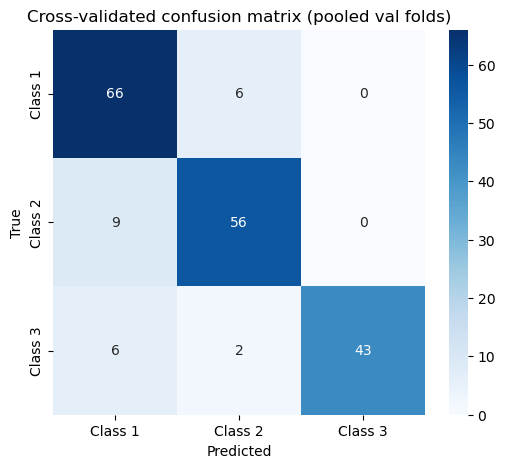

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt

all_fold_labels = np.array(all_fold_labels)
all_fold_preds = np.array(all_fold_preds)

cm = confusion_matrix(all_fold_labels, all_fold_preds)
print(cm)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Cross-validated confusion matrix (pooled val folds)')
plt.show()


In [57]:
print(classification_report(
    all_fold_labels,
    all_fold_preds,
    target_names=class_names,
    zero_division=0,
))


              precision    recall  f1-score   support

     Class 1       0.81      0.92      0.86        72
     Class 2       0.88      0.86      0.87        65
     Class 3       1.00      0.84      0.91        51

    accuracy                           0.88       188
   macro avg       0.90      0.87      0.88       188
weighted avg       0.89      0.88      0.88       188



In [65]:
# ============================================================
# POST-CV DEPLOYMENT STAGE
# Retrain one final model on ALL training data
# Then evaluate once on a completely separate held-out test set
# ============================================================

import copy
import json
import pandas as pd
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

# ------------------------------------------------------------
# USER SETTINGS
# ------------------------------------------------------------
# This must be a completely separate held-out test folder
deployment_test_root = '/Users/amani.khalid/Desktop/SRP 2/Real data/new/test'

# Use fixed channels from the pretrained checkpoint / CV folds
final_selected_channels = selected_channels

# Final save paths
final_model_path = os.path.join(save_dir, 'dtcwt_final_deployment_model.pth')
final_metrics_path = os.path.join(save_dir, 'dtcwt_final_deployment_metrics.json')

# Use same epochs as CV, or change if you want
final_head_epochs = head_epochs
final_full_epochs = full_epochs


# ------------------------------------------------------------
# CV SUMMARY
# ------------------------------------------------------------
results_df = pd.DataFrame(fold_results)
display(results_df)

print('\nCV summary:')
print(results_df[['val_acc', 'weighted_f1', 'balanced_acc']].agg(['mean', 'std', 'min', 'max']))

best_fold = max(
    fold_results,
    key=lambda x: (x['balanced_acc'], x['weighted_f1'], x['val_acc'])
)

print('\nSelected best CV fold:')
print(best_fold)


# ------------------------------------------------------------
# BUILD FULL TRAIN LOADER
# ------------------------------------------------------------
all_train_idx = np.arange(len(indexed_ds))

full_train_loader, _ = build_fold_dataloaders_fixed_channels(
    indexed_ds=indexed_ds,
    train_idx=all_train_idx,
    val_idx=all_train_idx[:min(8, len(all_train_idx))],  # dummy, unused
    batch_size=batch_size,
    selected_channels=final_selected_channels,
    include_lowpass=include_lowpass,
    num_workers=0,   # change to 2 if stable on your machine
)

print(f'\nFull training size: {len(all_train_idx)}')


# ------------------------------------------------------------
# BUILD HELD-OUT TEST LOADER
# ------------------------------------------------------------
test_base_ds = ImageFolder(root=deployment_test_root)

print('\nHeld-out test classes:', test_base_ds.classes)
print('Training classes     :', class_names)

if list(test_base_ds.classes) != list(class_names):
    raise ValueError(
        f"Mismatch between test classes {test_base_ds.classes} and training classes {class_names}"
    )

test_ds = DTCWTDatasetWithTransform(
    test_base_ds,
    selected_channels=final_selected_channels,
    include_lowpass=include_lowpass,
    transform=val_transform,
)

test_loader = DataLoader(
    test_ds,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,   # change to 2 if stable
    pin_memory=torch.cuda.is_available(),
)

print(f'Held-out test size: {len(test_ds)}')


# ------------------------------------------------------------
# FINAL TRAINING LOOP (NO VAL; CV ALREADY DONE)
# ------------------------------------------------------------
def run_final_training_stage(model, train_loader, optimizer, criterion, epochs, device):
    history = []

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)

        history.append({
            'epoch': epoch + 1,
            'train_loss': train_loss,
            'train_acc': train_acc,
        })

        print(
            f'  epoch {epoch+1}/{epochs} | '
            f'train loss {train_loss:.4f} acc {train_acc:.2f}%'
        )

    return copy.deepcopy(model.state_dict()), history


# ------------------------------------------------------------
# BUILD FINAL MODEL
# ------------------------------------------------------------
final_model = load_pretrained_dtcwt_for_finetune(
    pretrained_ckpt_path,
    num_classes=num_classes,
    in_channels=len(final_selected_channels),
    device=device,
)

criterion = nn.CrossEntropyLoss()


# ------------------------------------------------------------
# STAGE 1: HEAD-ONLY
# ------------------------------------------------------------
freeze_backbone_train_head(final_model)
final_optimizer_stage1 = make_optimizer_stage1(final_model)

print('\nFinal training - Stage 1: head-only')
final_state_stage1, final_hist_stage1 = run_final_training_stage(
    final_model,
    full_train_loader,
    final_optimizer_stage1,
    criterion,
    final_head_epochs,
    device,
)

final_model.load_state_dict(final_state_stage1)


# ------------------------------------------------------------
# STAGE 2: UNFREEZE LAST BLOCK
# ------------------------------------------------------------
unfreeze_last_block(final_model)
final_optimizer_stage2 = make_optimizer_stage2(final_model)

print('\nFinal training - Stage 2: unfreeze layer4 + classifier')
final_state_stage2, final_hist_stage2 = run_final_training_stage(
    final_model,
    full_train_loader,
    final_optimizer_stage2,
    criterion,
    final_full_epochs,
    device,
)

final_model.load_state_dict(final_state_stage2)


# ------------------------------------------------------------
# EVALUATE ON HELD-OUT TEST SET
# ------------------------------------------------------------
y_true_test, y_pred_test = collect_predictions(final_model, test_loader, device)

test_acc = (y_true_test == y_pred_test).mean() * 100.0
test_f1 = f1_score(y_true_test, y_pred_test, average='weighted', zero_division=0)
test_bal_acc = balanced_accuracy_score(y_true_test, y_pred_test)
test_cm = confusion_matrix(y_true_test, y_pred_test)

print('\n' + '=' * 80)
print('FINAL HELD-OUT TEST RESULTS')
print('=' * 80)
print(f'Test Accuracy     : {test_acc:.2f}%')
print(f'Test Weighted F1  : {test_f1:.4f}')
print(f'Test Balanced Acc : {test_bal_acc:.4f}')
print('\nConfusion Matrix:')
print(test_cm)

print('\nClassification Report:')
print(classification_report(
    y_true_test,
    y_pred_test,
    target_names=class_names,
    zero_division=0
))


# ------------------------------------------------------------
# SAVE FINAL DEPLOYMENT CHECKPOINT
# ------------------------------------------------------------
torch.save({
    'model_state_dict': final_model.state_dict(),
    'class_names': class_names,
    'selected_channels': final_selected_channels,
    'num_classes': num_classes,
    'best_cv_fold': int(best_fold['fold']),
    'best_cv_metrics': {
        'val_acc': float(best_fold['val_acc']),
        'weighted_f1': float(best_fold['weighted_f1']),
        'balanced_acc': float(best_fold['balanced_acc']),
    },
    'mean_cv_metrics': {
        'val_acc_mean': float(results_df['val_acc'].mean()),
        'val_acc_std': float(results_df['val_acc'].std()),
        'weighted_f1_mean': float(results_df['weighted_f1'].mean()),
        'weighted_f1_std': float(results_df['weighted_f1'].std()),
        'balanced_acc_mean': float(results_df['balanced_acc'].mean()),
        'balanced_acc_std': float(results_df['balanced_acc'].std()),
    },
    'test_metrics': {
        'test_acc': float(test_acc),
        'test_weighted_f1': float(test_f1),
        'test_balanced_acc': float(test_bal_acc),
    },
}, final_model_path)

print(f'\nSaved final deployment checkpoint to:\n{final_model_path}')


# ------------------------------------------------------------
# SAVE METRICS JSON
# ------------------------------------------------------------
with open(final_metrics_path, 'w') as f:
    json.dump({
        'best_cv_fold': int(best_fold['fold']),
        'best_cv_metrics': {
            'val_acc': float(best_fold['val_acc']),
            'weighted_f1': float(best_fold['weighted_f1']),
            'balanced_acc': float(best_fold['balanced_acc']),
        },
        'mean_cv_metrics': {
            'val_acc_mean': float(results_df['val_acc'].mean()),
            'val_acc_std': float(results_df['val_acc'].std()),
            'weighted_f1_mean': float(results_df['weighted_f1'].mean()),
            'weighted_f1_std': float(results_df['weighted_f1'].std()),
            'balanced_acc_mean': float(results_df['balanced_acc'].mean()),
            'balanced_acc_std': float(results_df['balanced_acc'].std()),
        },
        'test_metrics': {
            'test_acc': float(test_acc),
            'test_weighted_f1': float(test_f1),
            'test_balanced_acc': float(test_bal_acc),
        },
        'selected_channels': list(final_selected_channels),
        'class_names': list(class_names),
        'confusion_matrix': test_cm.tolist(),
    }, f, indent=2)

print(f'Saved deployment metrics to:\n{final_metrics_path}')

,fold,val_acc,weighted_f1,balanced_acc,selected_channels,n_train,n_val
0,1,81.578947,0.809092,0.782051,"[0, 10, 13, 14, 15, 16, 17, 18]",150,38
1,2,97.368421,0.973582,0.974359,"[0, 10, 13, 14, 15, 16, 17, 18]",150,38
2,3,89.473684,0.892982,0.904762,"[0, 10, 13, 14, 15, 16, 17, 18]",150,38
3,4,86.486486,0.867350,0.860073,"[0, 10, 13, 14, 15, 16, 17, 18]",151,37
4,5,83.783784,0.835348,0.838462,"[0, 10, 13, 14, 15, 16, 17, 18]",151,37



CV summary:
        val_acc  weighted_f1  balanced_acc
mean  87.738265     0.875671      0.871941
std    6.141939     0.063274      0.072299
min   81.578947     0.809092      0.782051
max   97.368421     0.973582      0.974359

Selected best CV fold:
{'fold': 2, 'val_acc': 97.36842105263158, 'weighted_f1': 0.9735823429541597, 'balanced_acc': 0.9743589743589745, 'selected_channels': [0, 10, 13, 14, 15, 16, 17, 18], 'n_train': 150, 'n_val': 38}

Full training size: 188

Held-out test classes: ['Class 1', 'Class 2', 'Class 3']
Training classes     : ['Class 1', 'Class 2', 'Class 3']
Held-out test size: 38


/var/folders/1z/0pgvgbnd26d_zjl_85nkwv840000gn/T/ipykernel_43204/2465023683.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(ckpt_path, map_location=dev

Loaded 318 tensors from checkpoint.
Skipped incompatible keys: ['model.fc.weight', 'model.fc.bias'] 
Missing keys: ['model.fc.weight', 'model.fc.bias'] 

Final training - Stage 1: head-only
  epoch 1/8 | train loss 0.7716 acc 64.89%
  epoch 2/8 | train loss 0.5802 acc 72.87%
  epoch 3/8 | train loss 0.5324 acc 76.60%
  epoch 4/8 | train loss 0.5256 acc 75.53%
  epoch 5/8 | train loss 0.4537 acc 76.06%
  epoch 6/8 | train loss 0.4689 acc 81.38%
  epoch 7/8 | train loss 0.4700 acc 79.26%
  epoch 8/8 | train loss 0.4170 acc 82.45%

Final training - Stage 2: unfreeze layer4 + classifier
  epoch 1/12 | train loss 0.4407 acc 78.72%
  epoch 2/12 | train loss 0.4351 acc 78.72%
  epoch 3/12 | train loss 0.3872 acc 84.57%
  epoch 4/12 | train loss 0.4774 acc 76.60%
  epoch 5/12 | train loss 0.3817 acc 82.98%
  epoch 6/12 | train loss 0.3646 acc 82.45%
  epoch 7/12 | train loss 0.4166 acc 77.13%
  epoch 8/12 | train loss 0.3878 acc 81.38%
  epoch 9/12 | train loss 0.3534 acc 81.38%
  epoch 10/12 

In [67]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, balanced_accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt


def load_saved_dtcwt_checkpoint_for_inference(ckpt_path, device):
    ckpt = torch.load(ckpt_path, map_location=device)
    class_names = ckpt['class_names']
    selected_channels = ckpt['selected_channels']
    num_classes = len(class_names)
    in_channels = len(selected_channels)

    model = DTCWTResNet50(num_classes=num_classes, in_channels=in_channels).to(device)
    state = ckpt.get('model_state_dict', ckpt.get('model_state', ckpt))
    model.load_state_dict(state, strict=True)
    model.eval()

    return model, class_names, selected_channels


def prepare_single_dtcwt_tensor(image_path, selected_channels, include_lowpass=True, transform=val_transform):
    img = Image.open(image_path).convert('RGB')
    display_img = img.copy()

    if transform is not None:
        img = transform(img)

    W = dtcwt_3level(img, include_lowpass=include_lowpass)
    W_sel = W[selected_channels, :, :]
    return display_img, W_sel.unsqueeze(0)


def predict_single_image(model, image_path, class_names, selected_channels, device, include_lowpass=True, transform=val_transform, show_image=True):
    display_img, x = prepare_single_dtcwt_tensor(
        image_path=image_path,
        selected_channels=selected_channels,
        include_lowpass=include_lowpass,
        transform=transform,
    )

    x = x.to(device)
    with torch.no_grad():
        logits = model(x)
        probs = torch.softmax(logits, dim=1).squeeze(0).cpu().numpy()
        pred_idx = int(np.argmax(probs))

    pred_class = class_names[pred_idx]
    result = {
        'image_path': image_path,
        'pred_index': pred_idx,
        'pred_class': pred_class,
        'probabilities': {class_names[i]: float(probs[i]) for i in range(len(class_names))},
    }

    if show_image:
        plt.figure(figsize=(4, 4))
        plt.imshow(display_img)
        plt.axis('off')
        plt.title(f'Predicted: {pred_class}')
        plt.show()

    print('Prediction:', pred_class)
    print('Class probabilities:')
    for k, v in result['probabilities'].items():
        print(f'  {k}: {v:.4f}')

    return result


def calculate_metrics_from_predictions(y_true, y_pred, class_names):
    acc = accuracy_score(y_true, y_pred)
    precision_w, recall_w, f1_w, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0
    )
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    report = classification_report(y_true, y_pred, target_names=class_names, zero_division=0)

    metrics = {
        'accuracy': float(acc),
        'weighted_precision': float(precision_w),
        'weighted_recall': float(recall_w),
        'weighted_f1': float(f1_w),
        'balanced_accuracy': float(bal_acc),
        'confusion_matrix': cm,
        'classification_report': report,
    }
    return metrics


def evaluate_model_on_loader(model, loader, class_names, device):
    y_true, y_pred = collect_predictions(model, loader, device)
    metrics = calculate_metrics_from_predictions(y_true, y_pred, class_names)

    print(f"Accuracy:           {metrics['accuracy']:.4f}")
    print(f"Weighted precision: {metrics['weighted_precision']:.4f}")
    print(f"Weighted recall:    {metrics['weighted_recall']:.4f}")
    print(f"Weighted F1:        {metrics['weighted_f1']:.4f}")
    print(f"Balanced accuracy:  {metrics['balanced_accuracy']:.4f}")
    print('\nClassification report:\n')
    print(metrics['classification_report'])

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        metrics['confusion_matrix'],
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
    )
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion matrix')
    plt.show()

    return metrics, y_true, y_pred


def build_inference_loader_from_folder(data_root, selected_channels, batch_size=16, include_lowpass=True, num_workers=0):
    ds = IndexedImageFolder(data_root)
    base_ds = FoldBaseDataset(ds, indices=range(len(ds)))
    eval_ds = DTCWTDatasetWithTransform(
        base_ds,
        selected_channels=selected_channels,
        include_lowpass=include_lowpass,
        transform=val_transform,
    )
    loader = DataLoader(
        eval_ds,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=torch.cuda.is_available(),
    )
    return ds, loader

In [69]:

# ------------------------------------------------------------
# EVALUATE ON HELD-OUT TEST SET
# ------------------------------------------------------------
y_true_test, y_pred_test = collect_predictions(final_model, test_loader, device)

test_acc = (y_true_test == y_pred_test).mean() * 100.0
test_f1 = f1_score(y_true_test, y_pred_test, average='weighted', zero_division=0)
test_bal_acc = balanced_accuracy_score(y_true_test, y_pred_test)
test_cm = confusion_matrix(y_true_test, y_pred_test)

print('\n' + '=' * 80)
print('FINAL HELD-OUT TEST RESULTS')
print('=' * 80)
print(f'Test Accuracy     : {test_acc:.2f}%')
print(f'Test Weighted F1  : {test_f1:.4f}')
print(f'Test Balanced Acc : {test_bal_acc:.4f}')
print('\nConfusion Matrix:')
print(test_cm)

print('\nClassification Report:')
print(classification_report(
    y_true_test,
    y_pred_test,
    target_names=class_names,
    zero_division=0
))



FINAL HELD-OUT TEST RESULTS
Test Accuracy     : 94.74%
Test Weighted F1  : 0.9476
Test Balanced Acc : 0.9373

Confusion Matrix:
[[16  0  0]
 [ 1 12  0]
 [ 1  0  8]]

Classification Report:
              precision    recall  f1-score   support

     Class 1       0.89      1.00      0.94        16
     Class 2       1.00      0.92      0.96        13
     Class 3       1.00      0.89      0.94         9

    accuracy                           0.95        38
   macro avg       0.96      0.94      0.95        38
weighted avg       0.95      0.95      0.95        38



/var/folders/1z/0pgvgbnd26d_zjl_85nkwv840000gn/T/ipykernel_43204/2481743676.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(ckpt_path, map_location=dev

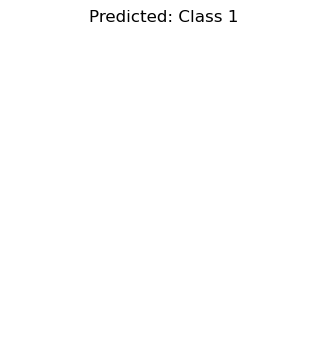

Prediction: Class 1
Class probabilities:
  Class 1: 0.4379
  Class 2: 0.2122
  Class 3: 0.3499


{'image_path': '/Users/amani.khalid/Desktop/SRP 2/Real data/Unclassified/0033-0051.png',
 'pred_index': 0,
 'pred_class': 'Class 1',
 'probabilities': {'Class 1': 0.4378654956817627,
  'Class 2': 0.2121979296207428,
  'Class 3': 0.34993651509284973}}

In [75]:
#Example 1: load one saved fold checkpoint for inference
inference_ckpt_path ='/Users/amani.khalid/Desktop/SRP 2/The model/dtcwt_finetune_cv/2/dtcwt_final_deployment_model.pth'
model_inf, inf_class_names, inf_selected_channels = load_saved_dtcwt_checkpoint_for_inference(inference_ckpt_path, device)

#Example 2: predict one image
test_image_path = '/Users/amani.khalid/Desktop/SRP 2/Real data/Unclassified/0033-0051.png'
single_result = predict_single_image(
    model=model_inf,
    image_path=test_image_path,
    class_names=inf_class_names,
    selected_channels=inf_selected_channels,
    device=device,
    include_lowpass=include_lowpass,
)
single_result

#Example 3: compute metrics on a whole folder organised like ImageFolder
# eval_root = 'path/to/eval_dataset_root'
# eval_indexed_ds, eval_loader = build_inference_loader_from_folder(
#     data_root=eval_root,
#     selected_channels=inf_selected_channels,
#     batch_size=batch_size,
#     include_lowpass=include_lowpass,
#     num_workers=0,
# )
# metrics, y_true_eval, y_pred_eval = evaluate_model_on_loader(
#     model=model_inf,
#     loader=eval_loader,
#     class_names=inf_class_names,
#     device=device,
# )



In [77]:
def test_labeled_image(image_path, true_label, ckpt_path, class_names, device):
    import torch
    import torch.nn.functional as F

    ckpt = torch.load(ckpt_path, map_location=device)  #, weights_only=True
    selected_channels = ckpt["selected_channels"]

    model = load_pretrained_dtcwt_for_finetune(
        ckpt_path,
        num_classes=len(class_names),
        in_channels=len(selected_channels),
        device=device,
    )
    model.load_state_dict(ckpt["model_state_dict"], strict=False)
    model.eval()

    # prepare_single_dtcwt_tensor returns (display_img, tensor)
    _, x = prepare_single_dtcwt_tensor(image_path, selected_channels)
    x = x.to(device)

    with torch.no_grad():
        out = model(x)
        probs = F.softmax(out, dim=1)
        pred_idx = torch.argmax(probs, dim=1).item()
        conf = probs[0, pred_idx].item()

    pred_label = class_names[pred_idx]

    return {
        "true_label": true_label,
        "pred_label": pred_label,
        "confidence": conf,
        "correct": pred_label == true_label
    }

In [79]:
class_names = ["Class 1", "Class 2", "Class 3"]

result = test_labeled_image(
    image_path= '/Users/amani.khalid/Desktop/SRP 2/Real data/Unclassified/0033-0051.png',
    true_label="Class 1",
    ckpt_path="/Users/amani.khalid/Desktop/SRP 2/The model/dtcwt_finetune_cv/2/dtcwt_final_deployment_model.pth",
    class_names=class_names,
    device=device)

print(result)
print(f"True: {result['true_label']}")
print(f"Pred: {result['pred_label']}")
print(f"Confidence: {result['confidence']:.2%}")
print(f"Correct: {result['correct']}")

/var/folders/1z/0pgvgbnd26d_zjl_85nkwv840000gn/T/ipykernel_43204/171680948.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(ckpt_path, map_location=devi

Loaded 320 tensors from checkpoint.
{'true_label': 'Class 1', 'pred_label': 'Class 1', 'confidence': 0.4378654956817627, 'correct': True}
True: Class 1
Pred: Class 1
Confidence: 43.79%
Correct: True


/var/folders/1z/0pgvgbnd26d_zjl_85nkwv840000gn/T/ipykernel_43204/2465023683.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(ckpt_path, map_location=dev

In [81]:
class_names = ["Class 1", "Class 2", "Class 3"]

result = test_labeled_image(
    image_path= '/Users/amani.khalid/Desktop/SRP 2/Real data/Unclassified/0208-0007.png',
    true_label="Class 2",
    ckpt_path="/Users/amani.khalid/Desktop/SRP 2/The model/dtcwt_finetune_cv/2/dtcwt_final_deployment_model.pth",
    class_names=class_names,
    device=device
)

print(result)
print(f"True: {result['true_label']}")
print(f"Pred: {result['pred_label']}")
print(f"Confidence: {result['confidence']:.2%}")
print(f"Correct: {result['correct']}")

/var/folders/1z/0pgvgbnd26d_zjl_85nkwv840000gn/T/ipykernel_43204/171680948.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(ckpt_path, map_location=devi

Loaded 320 tensors from checkpoint.
{'true_label': 'Class 2', 'pred_label': 'Class 1', 'confidence': 0.4378654956817627, 'correct': False}
True: Class 2
Pred: Class 1
Confidence: 43.79%
Correct: False


/var/folders/1z/0pgvgbnd26d_zjl_85nkwv840000gn/T/ipykernel_43204/2465023683.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(ckpt_path, map_location=dev

In [84]:
import os
import torch
import pandas as pd
from torchvision.datasets import ImageFolder

def predict_unlabeled_folder(
    model,
    data_root,
    selected_channels,
    class_names,
    device,
    batch_size=16,
    include_lowpass=True,
    num_workers=0,
    save_csv_path=None,
):
    """
    Predict classes for unlabeled images in a folder.

    Args:
        model: trained model
        data_root: folder containing images (can be flat or class-agnostic)
        selected_channels: DTCWT channels used during training
        class_names: list of class names
        device: torch device
        save_csv_path: optional path to save predictions CSV

    Returns:
        pandas DataFrame with predictions
    """

    # ------------------------------------------------------------
    # Handle unlabeled folder (no class subfolders)
    # ------------------------------------------------------------
    # Trick: wrap images into a fake single class so ImageFolder works
    temp_root = os.path.join(data_root, "__temp__")

    if not os.path.exists(temp_root):
        os.makedirs(temp_root, exist_ok=True)

        for fname in os.listdir(data_root):
            src = os.path.join(data_root, fname)
            dst = os.path.join(temp_root, fname)

            if os.path.isfile(src):
                try:
                    os.symlink(src, dst)
                except:
                    import shutil
                    shutil.copy(src, dst)

    # ------------------------------------------------------------
    # Build loader (reuse your pipeline)
    # ------------------------------------------------------------
    ds, loader = build_inference_loader_from_folder(
        temp_root,
        selected_channels=selected_channels,
        batch_size=batch_size,
        include_lowpass=include_lowpass,
        num_workers=num_workers,
    )

    # ------------------------------------------------------------
    # Run inference
    # ------------------------------------------------------------
    model.eval()
    all_preds = []
    all_probs = []
    image_paths = []

    with torch.no_grad():
        for xb, _ in loader:  # labels ignored
            xb = xb.to(device)

            logits = model(xb)
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(probs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    # ------------------------------------------------------------
    # Get file paths
    # ------------------------------------------------------------
    image_paths = [s[0] for s in ds.samples]

    # ------------------------------------------------------------
    # Build results DataFrame
    # ------------------------------------------------------------
    results = []

    for i, path in enumerate(image_paths):
        pred_idx = all_preds[i]
        pred_class = class_names[pred_idx]
        confidence = float(all_probs[i][pred_idx])

        results.append({
            "image_path": path,
            "predicted_class": pred_class,
            "confidence": confidence,
        })

    df = pd.DataFrame(results)

    # ------------------------------------------------------------
    # Optional save
    # ------------------------------------------------------------
    if save_csv_path is not None:
        df.to_csv(save_csv_path, index=False)
        print(f"Saved predictions to: {save_csv_path}")

    return df

In [86]:
pred_df = predict_unlabeled_folder(
    model=final_model,
    data_root='/Users/amani.khalid/Desktop/SRP 2/Real data/to be tested',
    selected_channels=final_selected_channels,
    class_names=class_names,
    device=device,
    batch_size=16,
    save_csv_path="predictions2.csv"
)

print(pred_df.head())

Saved predictions to: predictions2.csv
                                          image_path predicted_class  \
0  /Users/amani.khalid/Desktop/SRP 2/Real data/to...         Class 3   
1  /Users/amani.khalid/Desktop/SRP 2/Real data/to...         Class 1   
2  /Users/amani.khalid/Desktop/SRP 2/Real data/to...         Class 3   
3  /Users/amani.khalid/Desktop/SRP 2/Real data/to...         Class 1   
4  /Users/amani.khalid/Desktop/SRP 2/Real data/to...         Class 1   

   confidence  
0    0.987849  
1    0.437907  
2    0.767142  
3    0.798176  
4    0.944672  


### Notes

- This section fine-tunes the **saved DTCWT checkpoint** using **Stratified K-Fold CV**.
- The checkpoint loader accepts either `model_state_dict` or `model_state`, so it works with the save format already used earlier in this notebook.
- The DTCWT channels are re-selected from the **training fold only**, which avoids validation leakage.
- If your new dataset is very small, reduce `n_splits`, `batch_size`, or `C_keep` first.
